# Learning not to mix tasks in a fully connected network

In a fully connected network there are no distractors to remove: every connection may turn out useful. The question is
whether our method from `distractors.ipynb` learns to keep the two tasks' information apart instead of mixing it, and so
avoids interference. The goal is for it to do as well as with the ideal connectivity, which builds the problem's
structure in.

**Problem.** As in `nonstationary.ipynb`: 2-task multi-GEOFF where each task has 20 inputs ~ U(-1, 1), 10
zero-threshold teacher LTUs, and 10 outputs plus $N(0, 1)$ noise. Every 1000 steps, one task (chosen at random) has the
columns of its output weights permuted.

**Networks.** 40 inputs → 10 LTU hidden units → 20 linear outputs, each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 5 hidden units per task, each reading only its own task's inputs and feeding only its own
  task's outputs.

**Learners.** As in `nonstationary.ipynb`, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$:
- *ours*: centered hidden units with a matching centered backward pass, and input weights starting at
  $U(-\alpha_0, \alpha_0)$;
- *standard Autostep*: raw hidden units, and input weights starting LeCun uniform.

Each learner trains both networks. 1M steps and 30 seeds; seed $s$ gives every run the same teacher and the same
perturbations.

**Hypotheses**, on the excess MSE (above the noise floor) averaged over the last 10% of training, pooled over seeds:
- **H1**, ours learns not to mix: fully connected, ours is at most 1% above ours with ideal connectivity.
- **H2**, mixing is a real cost: fully connected, standard Autostep is more than 1% above standard Autostep with ideal
  connectivity.

**Diagnostics**, fixed in advance, for the fully connected runs:
1. *Path purity*: the share of each output's input → hidden → output path weight (the product of $|w|$ along the
   path) that starts at its own task's inputs, averaged over outputs. 1 means the tasks never mix, 1/2 that they mix
   evenly.
2. How the 10 hidden units split between the tasks at the end, counting each unit for the task whose outputs it feeds
   most. An uneven split costs capacity even without mixing.

In [1]:
from collections import Counter
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd
from phd.jax_core.tasks.multi_geoff import MultiGEOFFTask
from phd.jax_core.utils import stack_pytrees

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_INPUTS_PER_TASK = 20
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0
PERTURB_PERIOD = 1000                # steps between perturbations, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 5                # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records its mean loss, and |w| of every weight at its end

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # the loss is compared over the last 10% of training ...
LOSS_TOLERANCE = 0.01                # ... with this relative tolerance

In [3]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK

input_task = np.repeat(np.arange(N_TASKS), N_INPUTS_PER_TASK)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_OUTPUTS_PER_TASK)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum()} weights' for k in LAYERS))

ideal connectivity: w1 200 weights, w2 100 weights
fully connected: w1 400 weights, w2 200 weights


## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, y, masks, ours):
    # One online Autostep update. Returns the new learner and the squared error summed over outputs.
    def loss_fn(w):
        y_hat, aux = forward(w, x, learner, masks, ours)
        return 0.5 * jnp.sum((y_hat - y) ** 2), aux

    (loss, (source_values, mean, slope)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), 2.0 * loss

## Training

In [5]:
def train(key, task, masks, ours):
    # Step 1 on its own, then NUM_STEPS online steps in windows. Returns the per-output MSE of every window, and |w1| and
    # |w2| at the end of every window.
    def one_step(carry, _):
        learner, task = carry
        task, (x, y) = task.generate_batch(1)
        learner, sq_err = learner_step(learner, x[0], y[0], masks, ours)
        return (learner, task), sq_err

    def window(carry, _):
        carry, sq_err = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        return carry, (sq_err.mean() / N_OUTPUTS, {k: jnp.abs(carry[0].w[k]) for k in LAYERS})

    task, (x, y) = task.generate_batch(1)
    learner, _ = learner_step(init_learner(key, masks, ours), x[0], y[0], masks, ours)
    _, (mse, w) = jax.lax.scan(window, (learner, task), length=N_WINDOWS)
    return mse, w


def seeds():
    # Init keys and teachers. Seed s uses teacher s (and its perturbations) and init key s for every run, so runs are
    # paired.
    tasks = stack_pytrees([
        MultiGEOFFTask(N_TASKS, perturb_period=PERTURB_PERIOD, n_features_per_task=N_INPUTS_PER_TASK,
                       n_hidden_per_task=N_TEACHER_LTUS_PER_TASK, n_outputs_per_task=N_OUTPUTS_PER_TASK,
                       noise_std=NOISE_STD, seed=s)
        for s in range(N_SEEDS)])
    return jax.random.split(jax.random.PRNGKey(0), N_SEEDS), tasks


def run(network, ours):
    # Trains one learner (ours, or standard Autostep) on `network` (a key of MASKS) on every seed, vmapped into one scan.
    # Returns the excess MSE (seed, window), and |w1| and |w2| (seed, window, ...).
    keys, tasks = seeds()
    mse, w = jax.jit(jax.vmap(lambda key, task: train(key, task, MASKS[network], ours)))(keys, tasks)
    return {'excess_mse': np.asarray(mse) - NOISE_STD ** 2, **jax.tree.map(np.asarray, w)}

## Results

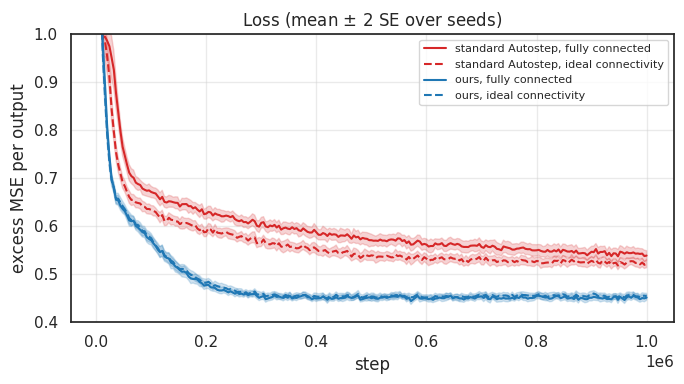

standard Autostep, fully connected     excess MSE 0.5437
standard Autostep, ideal connectivity  excess MSE 0.5240
ours, fully connected                  excess MSE 0.4508
ours, ideal connectivity               excess MSE 0.4547
H1, ours fully connected vs ideal connectivity: -0.8% (± 0.5%): held
H2, standard Autostep fully connected vs ideal connectivity: +3.8% (± 1.8%): held


In [6]:
runs = {'standard Autostep, fully connected': run('fully connected', ours=False),
        'standard Autostep, ideal connectivity': run('ideal connectivity', ours=False),
        'ours, fully connected': run('fully connected', ours=True),
        'ours, ideal connectivity': run('ideal connectivity', ours=True)}
# Color by learner; dashed for the ideal connectivity.
STYLES = {'standard Autostep, fully connected': ('tab:red', '-'),
          'standard Autostep, ideal connectivity': ('tab:red', '--'),
          'ours, fully connected': ('tab:blue', '-'), 'ours, ideal connectivity': ('tab:blue', '--')}

window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['excess_mse'].mean(0)
    sem = res['excess_mse'].std(0) / np.sqrt(N_SEEDS)
    color, linestyle = STYLES[label]
    plt.plot(window_ends, mean, color=color, ls=linestyle, lw=1.5, label=label)
    plt.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
plt.ylim(0.4, 1.0)                   # zoomed on the levels the learners reach; the loss starts above 1
plt.yticks(np.arange(0.4, 1.01, 0.1))
plt.xlabel('step')
plt.ylabel('excess MSE per output')
plt.title('Loss (mean $\\pm$ 2 SE over seeds)')
plt.grid(alpha=0.4)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's excess MSE over the last FINAL_FRACTION of training.
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
loss = {label: res['excess_mse'][:, final].mean(1) for label, res in runs.items()}
for label, l in loss.items():
    print(f'{label:<38} excess MSE {l.mean():.4f}')


def gap(learner):
    # The per-seed gap of the fully connected run to the ideal connectivity on the same seed, relative to the ideal
    # run's mean: its mean and 2 SE.
    reference = loss[f'{learner}, ideal connectivity']
    g = (loss[f'{learner}, fully connected'] - reference) / reference.mean()
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


held = lambda ok: 'held' if ok else 'failed'
h1, h1_se = gap('ours')
h2, h2_se = gap('standard Autostep')
print(f'H1, ours fully connected vs ideal connectivity: {h1:+.1%} (± {h1_se:.1%}): {held(h1 <= LOSS_TOLERANCE)}')
print(f'H2, standard Autostep fully connected vs ideal connectivity: {h2:+.1%} (± {h2_se:.1%}): '
      f'{held(h2 > LOSS_TOLERANCE)}')

### Diagnostics: mixing and unit allocation

Path purity over training for the fully connected runs (mean over seeds, with the 5th to 95th percentile over seeds
shaded), and how the hidden units split between the tasks at the end.

standard Autostep, fully connected: hidden units per task at the end, (fewer, more): number of seeds {(5, 5): 11, (3, 7): 4, (2, 8): 1, (4, 6): 14}
ours, fully connected: hidden units per task at the end, (fewer, more): number of seeds {(4, 6): 18, (3, 7): 3, (1, 9): 1, (2, 8): 5, (5, 5): 3}


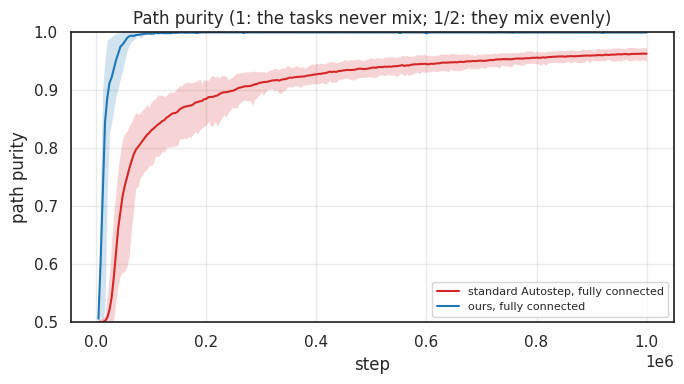

In [7]:
def path_purity(w1, w2):
    # The share of each output's input -> hidden -> output path weight (the product of |w| along the path) that starts at
    # its own task's inputs, averaged over outputs. Biases are left out.
    paths = w2[..., :-1] @ w1[..., :-1]                                      # (..., output, input)
    same = output_task[:, None] == input_task[None, :]
    return ((paths * same).sum(-1) / paths.sum(-1)).mean(-1)


def units_per_task(w2):
    # How many hidden units feed each task's outputs most (by the sum of |w| to that task's outputs), sorted.
    feeds = np.stack([w2[..., output_task == t, :-1].sum(-2) for t in range(N_TASKS)], -1)    # (..., hidden, task)
    return np.sort(np.stack([(feeds.argmax(-1) == t).sum(-1) for t in range(N_TASKS)], -1), -1)


plt.figure(figsize=(7, 4))
for label in ('standard Autostep, fully connected', 'ours, fully connected'):
    purity = path_purity(runs[label]['w1'], runs[label]['w2'])                # (seed, window)
    color, _ = STYLES[label]
    plt.plot(window_ends, purity.mean(0), color=color, lw=1.5, label=label)
    plt.fill_between(window_ends, *np.percentile(purity, [5, 95], axis=0), color=color, alpha=0.2, lw=0)
    splits = Counter(map(tuple, units_per_task(runs[label]['w2'][:, -1]).tolist()))
    print(f'{label}: hidden units per task at the end, (fewer, more): number of seeds {dict(splits)}')
plt.ylim(0.5, 1.0)
plt.xlabel('step')
plt.ylabel('path purity')
plt.title('Path purity (1: the tasks never mix; 1/2: they mix evenly)')
plt.grid(alpha=0.4)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Results

- **H1 held.** Fully connected, ours is −0.8% (± 0.5%, 2 SE over paired seeds) against ours with ideal connectivity:
  slightly better, not just as good.
- **H2 held.** Fully connected, standard Autostep is +3.8% (± 1.8%) above itself with ideal connectivity.
- **Mixing.** Ours stops mixing the tasks almost at once: its path purity is near 1 by about 100k steps and stays
  there. Standard Autostep's climbs slowly and reaches about 0.96 by 1M steps.
- **Unit allocation.** Ours rarely splits its hidden units evenly (5/5 in 3 of 30 seeds, 4/6 in 18, more uneven in
  9), yet it beats the ideal network, which is fixed at 5/5. Why it does slightly better is not known; one possibility
  is that a flexible split suits teachers of unequal difficulty. A unit is counted for the task it feeds most, even if
  it feeds both only weakly.